# The North Face — Recommandation et structuration du catalogue

**Contexte**  
Projet de data science (NLP non supervisé) réalisé sur un corpus de **500 fiches produit** du catalogue The North Face.  
L'objectif métier : augmenter les ventes en ligne avec une section « Vous aimerez aussi » et une navigation par catégories mieux adaptée au catalogue.

**Objectifs**
| # | Livrable | Technique |
|---|----------|-----------|
| 1 | Identifier des groupes de produits aux descriptions proches | TF-IDF + clustering **DBSCAN** (distance cosinus) |
| 2 | Recommander des produits similaires à un produit consulté | Clusters + **similarité cosinus** |
| 3 | Extraire les thèmes latents des descriptions | **LSA** (`TruncatedSVD`) |


**Etapes du projet**
1. Imports et configuration
2. Exploration et préparation des données
3. Clustering DBSCAN
4. Système de recommandation
5. Topic modeling (LSA)
6. Conclusion et limites


## 1. Imports et configuration

In [1]:
from pathlib import Path
import sys
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from wordcloud import WordCloud
from matplotlib.colors import LinearSegmentedColormap

# Accéder au dossier src/ depuis notebooks/
sys.path.append(str(Path("..").resolve()))
from src.preprocessing import (  # noqa: E402
    BOILERPLATE_PATTERNS, CUSTOM_STOP_WORDS,
    clean_corpus, clean_text, load_nlp,
)
from src.recommender import (  # noqa: E402
    build_similarity_matrix, find_similar_items,
)

ACCENT = "#DA2427"  # Rouge The North Face
RANDOM_STATE = 42

DATA_PATH = Path("..") / "data" / "sample-data.csv"
ASSETS_DIR = Path("..") / "assets"
IMAGES_DIR = ASSETS_DIR / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

# Palette adaptée à un fond blanc (le dossier est imprimé)
tnf_cmap = LinearSegmentedColormap.from_list(
    "tnf", ["#7A7A7A", "#222222", "#DA2427"], N=256
)

In [2]:
def save_figure(filename):
    """
    Sauvegarde la figure courante dans assets/images
    et l'affiche si SHOW_PLOTS est activé.

    Paramètres :
        - filename : str
            Nom du fichier image (ex. "k_distance.png")
    """
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

## 2. Exploration et préparation des données

In [3]:
try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    print(
        "Fichier introuvable. "
    )
    raise

print(
    f"Dataset chargé : {df.shape[0]} produit(s); "
    f"{df.shape[1]} colonne(s)"
)
display(df.head(3))

Dataset chargé : 500 produit(s); 2 colonne(s)


,id,description
0,1,Active classic boxers - There's a reason why o...
1,2,Active sport boxer briefs - Skinning up Glory ...
2,3,Active sport briefs - These superbreathable no...


### 2.1 Aperçu

In [4]:
print("Valeurs manquantes :")
print(df.isnull().sum())
print(f"\nDescriptions uniques : {df['description'].nunique()}")
print(
    f"Identifiants uniques : {df['id'].nunique()} "
)

# Contrôle de la préseznce de HTML ?
n_html = df["description"].str.contains(r"<[^>]+>").sum()
print(f"Descriptions contenant des balises HTML : {n_html} / {len(df)}")

# Nom du produit = texte avant le premier " - "
df["nom"] = df["description"].str.split(" - ").str[0]
display(df[["id", "nom"]].head())

Valeurs manquantes :
id             0
description    0
dtype: int64

Descriptions uniques : 500
Identifiants uniques : 500 
Descriptions contenant des balises HTML : 500 / 500


,id,nom
0,1,Active classic boxers
1,2,Active sport boxer briefs
2,3,Active sport briefs
3,4,Alpine guide pants
4,5,Alpine wind jkt


### 2.2 Preprocessing du texte
Le contrôle précédent montre que **toutes les fiches contiennent du HTML** et partagent un gabarit
(« Details », « Fabric », « Weight », « Made in … », phrase *Common Threads Recycling Program*).
Ces éléments ne décrivent pas le produit : ils sont supprimés (`src/preprocessing.py`) **avant** la lemmatisation,
sinon ils dominent le TF-IDF et pollueraient clusters et topics.

In [5]:
nlp = load_nlp()

In [6]:
# Les fonctions de nettoyage sont dans src/preprocessing.py
print("Motifs supprimés avant lemmatisation :")
for pattern in BOILERPLATE_PATTERNS:
    print(f"  - {pattern}")

Motifs supprimés avant lemmatisation :
  - <[^>]+>
  - Recyclable through the Common Threads Recycling Program
  - \b(?:Details|Fabric|Weight):
  - \(\s*\d+\s*g\s*[\d.]+\s*oz\s*\)
  - Made in [A-Za-z ]+\.\s*$


In [7]:
phrase_test = (
    "<b>Details:</b> The North Face creates amazing jackets "
    "for running in the mountains! Made in Vietnam."
)
print(f"Avant : {phrase_test}")
print(f"Après : {clean_text(phrase_test, nlp)}")

Avant : <b>Details:</b> The North Face creates amazing jackets for running in the mountains! Made in Vietnam.
Après : north face create amazing jacket run mountain


In [8]:
print("Nettoyage des descriptions")

df["description_nettoyee"] = clean_corpus(df["description"], nlp)

print("Nettoyage terminé :")
print("\n--- AVANT ---")
print(df["description"].iloc[10][:300])
print("\n--- APRÈS ---")
print(df["description_nettoyee"].iloc[10][:300])

Nettoyage des descriptions
Nettoyage terminé :

--- AVANT ---
Baby sunshade top - Soft, stretchy polyester fabric is fast wicking, quick drying and breathable <br><br><b>Details:</b><ul> <li>Lap shoulders relax the silhouette </li> <li>Extended roll-down cuffs accommodate growth spurts; drop hem waist provides extra coverage</li></ul><br><br><b>Fabric: </b>4.3

--- APRÈS ---
baby sunshade soft stretchy polyester fabric fast wicke quick drying breathable lap shoulder relax silhouette extended roll cuff accommodate growth spurt drop hem waist provide extra coverage polyester jersey


### 2.3 Stop words métier

Après nettoyage, on repère les termes génériques sans valeur descriptive présents dans une grande part du catalogue : ils ne permettent pas de distinguer deux produits.

In [11]:
doc_freq = (
    df["description_nettoyee"]
    .str.split()
    .apply(set)
    .explode()
    .value_counts()
    / len(df)
)
print("Termes présents dans le plus grand nombre de fiches :")
print((doc_freq.head(10) * 100).round(1).astype(str) + " %")

# "fabric", "provide" et "feature" reviennent dans les fiches
# sans décrire le produit (liste définie dans src/preprocessing.py)
print(f"\nStop words métier retenus : {CUSTOM_STOP_WORDS}")

Termes présents dans le plus grand nombre de fiches :
description_nettoyee
fabric       57.6 %
soft         52.0 %
pocket       51.2 %
polyester    47.6 %
durable      41.8 %
dry          39.0 %
seam         38.4 %
provide      37.0 %
recycle      36.6 %
fit          35.6 %
Name: count, dtype: str

Stop words métier retenus : ['fabric', 'provide', 'feature']


**Interprétation** Quelques termes reviennent dans plus d'une fiche sur trois (`fabric` 58 %, `soft` 52 %, `pocket` 51 %). On ne retire que ceux sans valeur descriptive (`fabric`, `provide`, `feature`). `pocket`, `soft` ou `polyester` restent, car ils renseignent sur le produit et sont de toute façon atténués par l'IDF.

### 2.4 Vectorisation TF-IDF

In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words=CUSTOM_STOP_WORDS,
    min_df=2,           # ignore les termes présents dans moins de 2 fiches
    sublinear_tf=True,  # log(TF) pour atténuer les fréquences élevées
)

print("Vectorisation TF-IDF")
tfidf_matrix = tfidf_vectorizer.fit_transform(
    df["description_nettoyee"]
)
feature_names = tfidf_vectorizer.get_feature_names_out()

density = tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])
print(f"Matrice TF-IDF créée : {tfidf_matrix.shape}")
print(f"Densité : {density:.4f}")

Vectorisation TF-IDF
Matrice TF-IDF créée : (500, 2073)
Densité : 0.0268


**Interprétation** La matrice est très creuse (densité de 2,7 %) : chaque fiche n'utilise qu'environ 56 des 2 073 termes. Les termes les plus pondérés décrivent des matières (organic, cotton, polyester, spandex), des détails de construction (pocket, seam, inseam) et des traitements (DWR, water, finish).

,Terme,TF-IDF moyen
0,organic,0.0482
1,pocket,0.0458
2,cotton,0.0439
3,polyester,0.0382
4,soft,0.0356
5,seam,0.0329
6,spandex,0.0326
7,shirt,0.0326
8,recycle,0.0302
9,shoulder,0.0289


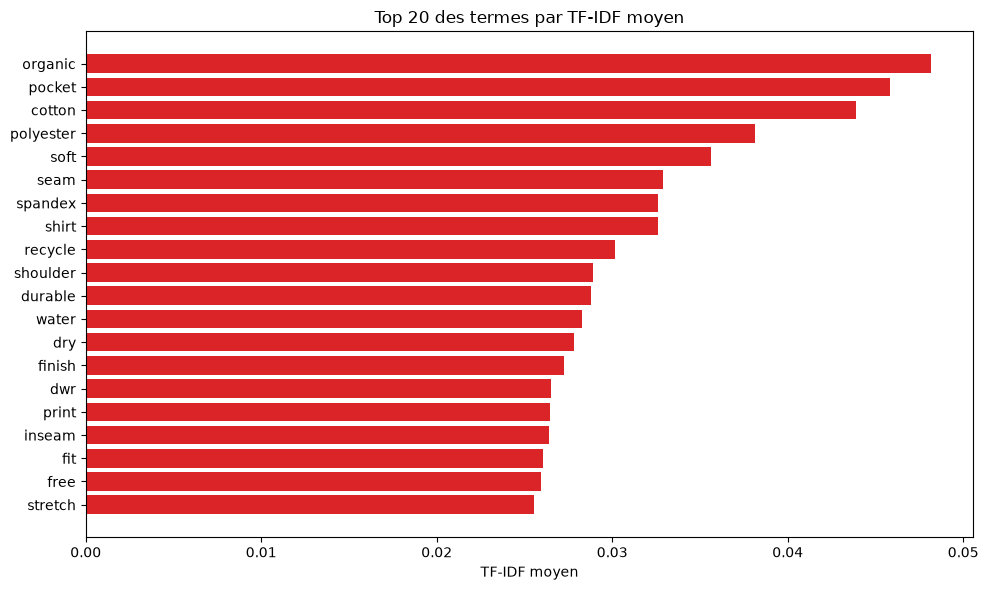

In [40]:
mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).ravel()
top_indices = mean_tfidf.argsort()[::-1][:20]

top_terms = pd.DataFrame({
    "Terme": feature_names[top_indices],
    "TF-IDF moyen": mean_tfidf[top_indices].round(4),
})
display(top_terms)

plt.figure(figsize=(10, 6))
plt.barh(
    feature_names[top_indices][::-1],
    mean_tfidf[top_indices][::-1],
    color=ACCENT,
)
plt.title("Top 20 des termes par TF-IDF moyen")
plt.xlabel("TF-IDF moyen")
save_figure("01_tfidf_top20.png")

## 3. Clustering DBSCAN

DBSCAN avec distance **cosinus**. Un premier essai avec `eps = 0.2` montre que ce seuil est beaucoup trop strict.

In [41]:
dbscan = DBSCAN(
    eps=0.2,
    min_samples=3,
    metric="cosine",
)

print("Entraînement DBSCAN avec eps = 0.2")
clusters = dbscan.fit_predict(tfidf_matrix)

n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print(f"Résultat : {n_clusters} clusters identifiés.")
print(
    f"Produits non classés (bruit, cluster -1) : "
    f"{n_noise} ({n_noise / len(df) * 100:.1f} %)"
)

Entraînement DBSCAN avec eps = 0.2
Résultat : 13 clusters identifiés.
Produits non classés (bruit, cluster -1) : 449 (89.8 %)


**Interprétation** À eps = 0,2 (similarité cosinus ≥ 0,8), seuls 51 produits (10 %) ont assez de voisins : DBSCAN ne retrouve que des quasi-doublons, probablement des variantes d'un même article. Il faut élargir eps.

### 3.1 Recherche des hyperparamètres

Un `eps` trop grand fait fusionner presque tout le catalogue dans **un seul cluster géant**. On balaie donc `eps` et `min_samples`, et on suit pour chaque couple : le nombre de clusters, le taux de bruit, la part du plus gros cluster et la silhouette.

Critères de sélection (énoncé + garde-fou sur le cluster géant) :
- 10 à 20 clusters
- au plus 25 % de bruit
- aucun cluster ne dépasse 30 % du catalogue
- parmi les couples retenus : meilleure silhouette

In [42]:
MIN_CLUSTERS, MAX_CLUSTERS = 10, 20
MAX_NOISE_PCT = 25
MAX_BIGGEST_CLUSTER_PCT = 30


def evaluate_dbscan(matrix, eps, min_samples):
    """
    Entraîne DBSCAN et résume la qualité du clustering.

    Paramètres :
        - matrix : matrice TF-IDF (sparse)
        - eps : float
            Distance cosinus maximale entre voisins
        - min_samples : int
            Nombre minimal de voisins pour former un cluster

    Retourne :
        - dict
            Métriques du couple (eps, min_samples)
    """
    labels = DBSCAN(
        eps=eps, min_samples=min_samples, metric="cosine"
    ).fit_predict(matrix)

    mask = labels != -1
    n_found = len(set(labels[mask]))
    biggest = (
        pd.Series(labels[mask]).value_counts().iloc[0]
        if n_found > 0 else 0
    )
    # La silhouette exige au moins 2 clusters
    sil = (
        silhouette_score(matrix[mask], labels[mask], metric="cosine")
        if n_found > 1 else np.nan
    )

    return {
        "eps": eps,
        "min_samples": min_samples,
        "n_clusters": n_found,
        "bruit_pct": (~mask).mean() * 100,
        "plus_gros_cluster_pct": biggest / len(labels) * 100,
        "silhouette": sil,
    }

In [43]:
eps_values = np.round(np.arange(0.60, 0.78, 0.02), 2)
min_samples_values = [3, 4, 5, 6, 7, 8]

grid_results = pd.DataFrame([
    evaluate_dbscan(tfidf_matrix, eps, min_samples)
    for min_samples in min_samples_values
    for eps in eps_values
])
grid_results.to_csv(ASSETS_DIR / "dbscan_grid.csv", index=False)

eligible = grid_results[
    grid_results["n_clusters"].between(MIN_CLUSTERS, MAX_CLUSTERS)
    & (grid_results["bruit_pct"] <= MAX_NOISE_PCT)
    & (grid_results["plus_gros_cluster_pct"] <= MAX_BIGGEST_CLUSTER_PCT)
].sort_values("silhouette", ascending=False)

print(
    f"{len(grid_results)} couples testés, "
    f"{len(eligible)} respectent les critères :"
)
display(eligible.round(3))

60 couples testés, 1 respectent les critères :


,eps,min_samples,n_clusters,bruit_pct,plus_gros_cluster_pct,silhouette
24,0.68,5,20,23.4,25.4,0.215


Couple retenu : eps = 0.68, min_samples = 5


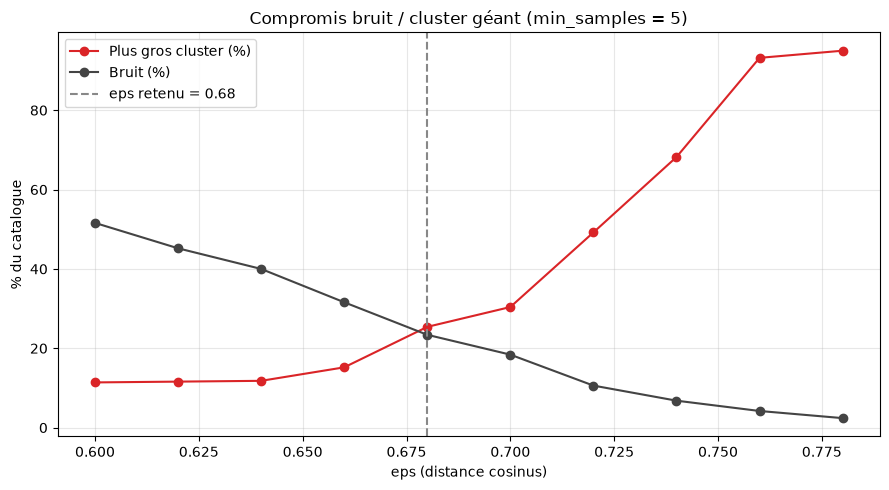

In [44]:
best_params = eligible.iloc[0]
best_eps = float(best_params["eps"])
best_min_samples = int(best_params["min_samples"])

print(
    f"Couple retenu : eps = {best_eps}, "
    f"min_samples = {best_min_samples}"
)

# Évolution du cluster géant et du bruit selon eps (min_samples retenu)
subset = grid_results[grid_results["min_samples"] == best_min_samples]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(subset["eps"], subset["plus_gros_cluster_pct"],
        marker="o", color=ACCENT, label="Plus gros cluster (%)")
ax.plot(subset["eps"], subset["bruit_pct"],
        marker="o", color="#444444", label="Bruit (%)")
ax.axvline(best_eps, color="#888888", linestyle="--",
           label=f"eps retenu = {best_eps}")
ax.set_xlabel("eps (distance cosinus)")
ax.set_ylabel("% du catalogue")
ax.set_title(
    f"Compromis bruit / cluster géant (min_samples = {best_min_samples})"
)
ax.legend()
ax.grid(True, alpha=0.3)
save_figure("02_eps_tradeoff.png")

**Interprétation** Un seul couple sur 60 respecte les critères (eps = 0,68, min_samples = 5). La sélection par silhouette est donc de fait sans objet, et le choix est dicté par les contraintes. La fenêtre est étroite : à eps = 0,66, le bruit atteint environ 32 %, et à 0,70 le plus gros cluster passe à environ 30 %, puis 49 % à 0,72 et plus de 90 % à 0,76. Au-delà de 0,68, les clusters fusionnent par effet de chaîne.

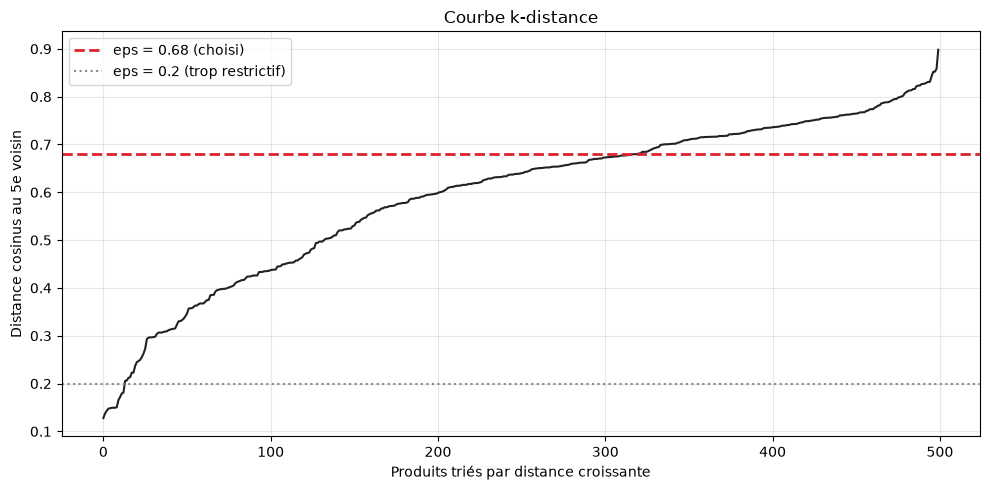

In [45]:
# Courbe k-distance : vérification visuelle du choix de eps
# (k = min_samples, le point lui-même compte parmi ses voisins)
k = best_min_samples
nn = NearestNeighbors(n_neighbors=k, metric="cosine")
nn.fit(tfidf_matrix)
distances, _ = nn.kneighbors(tfidf_matrix)
sorted_distances = np.sort(distances[:, k - 1])

plt.figure(figsize=(10, 5))
plt.plot(sorted_distances, color="#222222", linewidth=1.5)
plt.axhline(
    y=best_eps, color=ACCENT, linestyle="--", linewidth=2,
    label=f"eps = {best_eps} (choisi)",
)
plt.axhline(
    y=0.2, color="#888888", linestyle=":", linewidth=1.5,
    label="eps = 0.2 (trop restrictif)",
)
plt.xlabel("Produits triés par distance croissante")
plt.ylabel(f"Distance cosinus au {k}e voisin")
plt.title("Courbe k-distance")
plt.legend()
plt.grid(True, alpha=0.3)
save_figure("03_k_distance.png")

**Interprétation** La courbe n'a pas de coude net : elle ne permet pas de fixer eps, seulement de le situer. Avec eps = 0,68, environ 64 % des produits (≈ 320) ont au moins 5 voisins proches, le reste étant bruit ou bordure. Avec eps = 0,2, seule une douzaine de produits remplissent cette condition.

In [46]:
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric="cosine")
df["cluster"] = dbscan.fit_predict(tfidf_matrix)

n_clusters_final = len(set(df["cluster"])) - (
    1 if -1 in df["cluster"].values else 0
)
n_noise_final = (df["cluster"] == -1).sum()
pct_noise = n_noise_final / len(df) * 100

print(f"Clusters : {n_clusters_final}")
print(f"Bruit restant : {n_noise_final} ({pct_noise:.1f} %)")
print("\nDistribution des clusters :")
print(df["cluster"].value_counts())

Clusters : 20
Bruit restant : 117 (23.4 %)

Distribution des clusters :
cluster
 0     127
-1     117
 5      59
 4      40
 1      27
 10     15
 16     11
 17     10
 15     10
 2       9
 3       9
 9       9
 14      8
 6       8
 7       8
 13      7
 8       6
 18      5
 11      5
 12      5
 19      5
Name: count, dtype: int64


In [47]:
# Silhouette sur les produits classés (hors outliers)
mask = df["cluster"] != -1
sil_score = silhouette_score(
    tfidf_matrix[mask.values],
    df.loc[mask, "cluster"].values,
    metric="cosine",
)

print(f"Silhouette Score (eps={best_eps}) : {sil_score:.4f}")
if sil_score < 0.25:
    verdict = "structure faible : les clusters se chevauchent"
elif sil_score < 0.5:
    verdict = "structure modérée : clusters partiellement distincts"
else:
    verdict = "structure nette : clusters bien séparés"
print(f"Interprétation : {verdict}.")
print(
    f"Produits évalués : {mask.sum()} / {len(df)} "
    f"({mask.sum() / len(df) * 100:.1f} % du catalogue)."
)

Silhouette Score (eps=0.68) : 0.2150
Interprétation : structure faible : les clusters se chevauchent.
Produits évalués : 383 / 500 (76.6 % du catalogue).


### Interprétation des clusters

In [48]:
def get_term_weights(row_mask, n_terms=40):
    """
    Poids TF-IDF moyens des termes d'un groupe de produits.

    Paramètres :
        - row_mask : array de booléens
            Produits du groupe
        - n_terms : int
            Nombre de termes conservés

    Retourne :
        - dict
            {terme : poids moyen}, trié par poids décroissant
    """
    weights = np.asarray(tfidf_matrix[row_mask].mean(axis=0)).ravel()
    top = weights.argsort()[::-1][:n_terms]
    return {feature_names[i]: weights[i] for i in top}


CLUSTER_NAMES = {
    0: 'Pantalons, shorts et vestes outdoor (fourre-tout)',
    5: 'T-shirts graphiques coton bio',
    4: 'Sous-vêtements et sous-couches Capilene',
    1: 'Sacs et accessoires de transport',
    10: 'Hauts mérinos',
    16: 'Robes et jupes',
    17: 'Brassières et hauts de maillot',
    15: 'Hauts tencel et coton bio',
    2: 'Bas de maillot de bain',
    3: 'Chapeaux et casquettes',
    9: 'Chaussettes',
    14: 'Polaires et pulls zippés',
    6: 'Doudounes et vestes isolées',
    7: 'Posters',
    13: 'Waders',
    8: 'Rashguards',
    18: 'Gilets et vestes Synch',
    11: 'Chaussures',
    12: 'Hauts anti-UV Runshade',
    19: 'Gamme Vitaliti',
}

cluster_ids = (
    df.loc[df["cluster"] != -1, "cluster"].value_counts().index.tolist()
)

cluster_summary = pd.DataFrame([
    {
        "cluster": cid,
        "nom": CLUSTER_NAMES.get(cid, ""),
        "produits": (df["cluster"] == cid).sum(),
        "termes_cles": ", ".join(
            list(get_term_weights((df["cluster"] == cid).values, 8))
        ),
        "exemples": " | ".join(
            df.loc[df["cluster"] == cid, "nom"].head(3)
        ),
    }
    for cid in cluster_ids
])
pd.set_option("display.max_colwidth", 90)
display(cluster_summary)

,cluster,nom,produits,termes_cles,exemples
0,0,"Pantalons, shorts et vestes outdoor (fourre-tout)",127,"pocket, inseam, dwr, finish, closure, water, durable, zip",Alpine guide pants | Alpine wind jkt | Ascensionist jkt
1,5,T-shirts graphiques coton bio,59,"ringspun, phthalate, tap, shirt, ink, print, screen, free",City by the sea t-shirt | Dragoons t-shirt | Fish frenzy t-shirt
2,4,Sous-vêtements et sous-couches Capilene,40,"gladiodor, natural, control, capilene, odor, garment, baselayer, fast",Active classic boxers | Active sport briefs | Cap 1 bottoms
3,1,Sacs et accessoires de transport,27,"polyurethane, deni, coating, strap, compartment, main, mesh, pocket",Atom | Crosstown | Freewheeler
4,10,Hauts mérinos,15,"merino, wash, wool, slow, machine, odor, naturally, lie",Merino 1 crew | Merino 1 t-shirt | Merino 2 polo
5,16,Robes et jupes,11,"dress, bodice, knee, drape, fall, shirr, smooth, tie",Bandha dress | Bandha top | Lithia dress
6,17,Brassières et hauts de maillot,10,"bra, bibiana, spandex, style, shelf, cup, support, racerback",Active mesh bra | Solid bibiana 1 piece | Solid bibiana top
7,15,Hauts tencel et coton bio,10,"tencel, organic, plait, jersey, cotton, versatiliti, neck, astrid",Astrid tank | Simply organic tank | Versatili-tee
8,2,Bas de maillot de bain,9,"coverage, btm, line, improve, spandex, rise, hip, medium",Print banded betina btm | Solid adour btm | Solid betina btm
9,3,Chapeaux et casquettes,9,"headband, glare, coolmax, brim, underbill, dark, buckle, rear",Beach bucket | Bucket hat | Logo hat


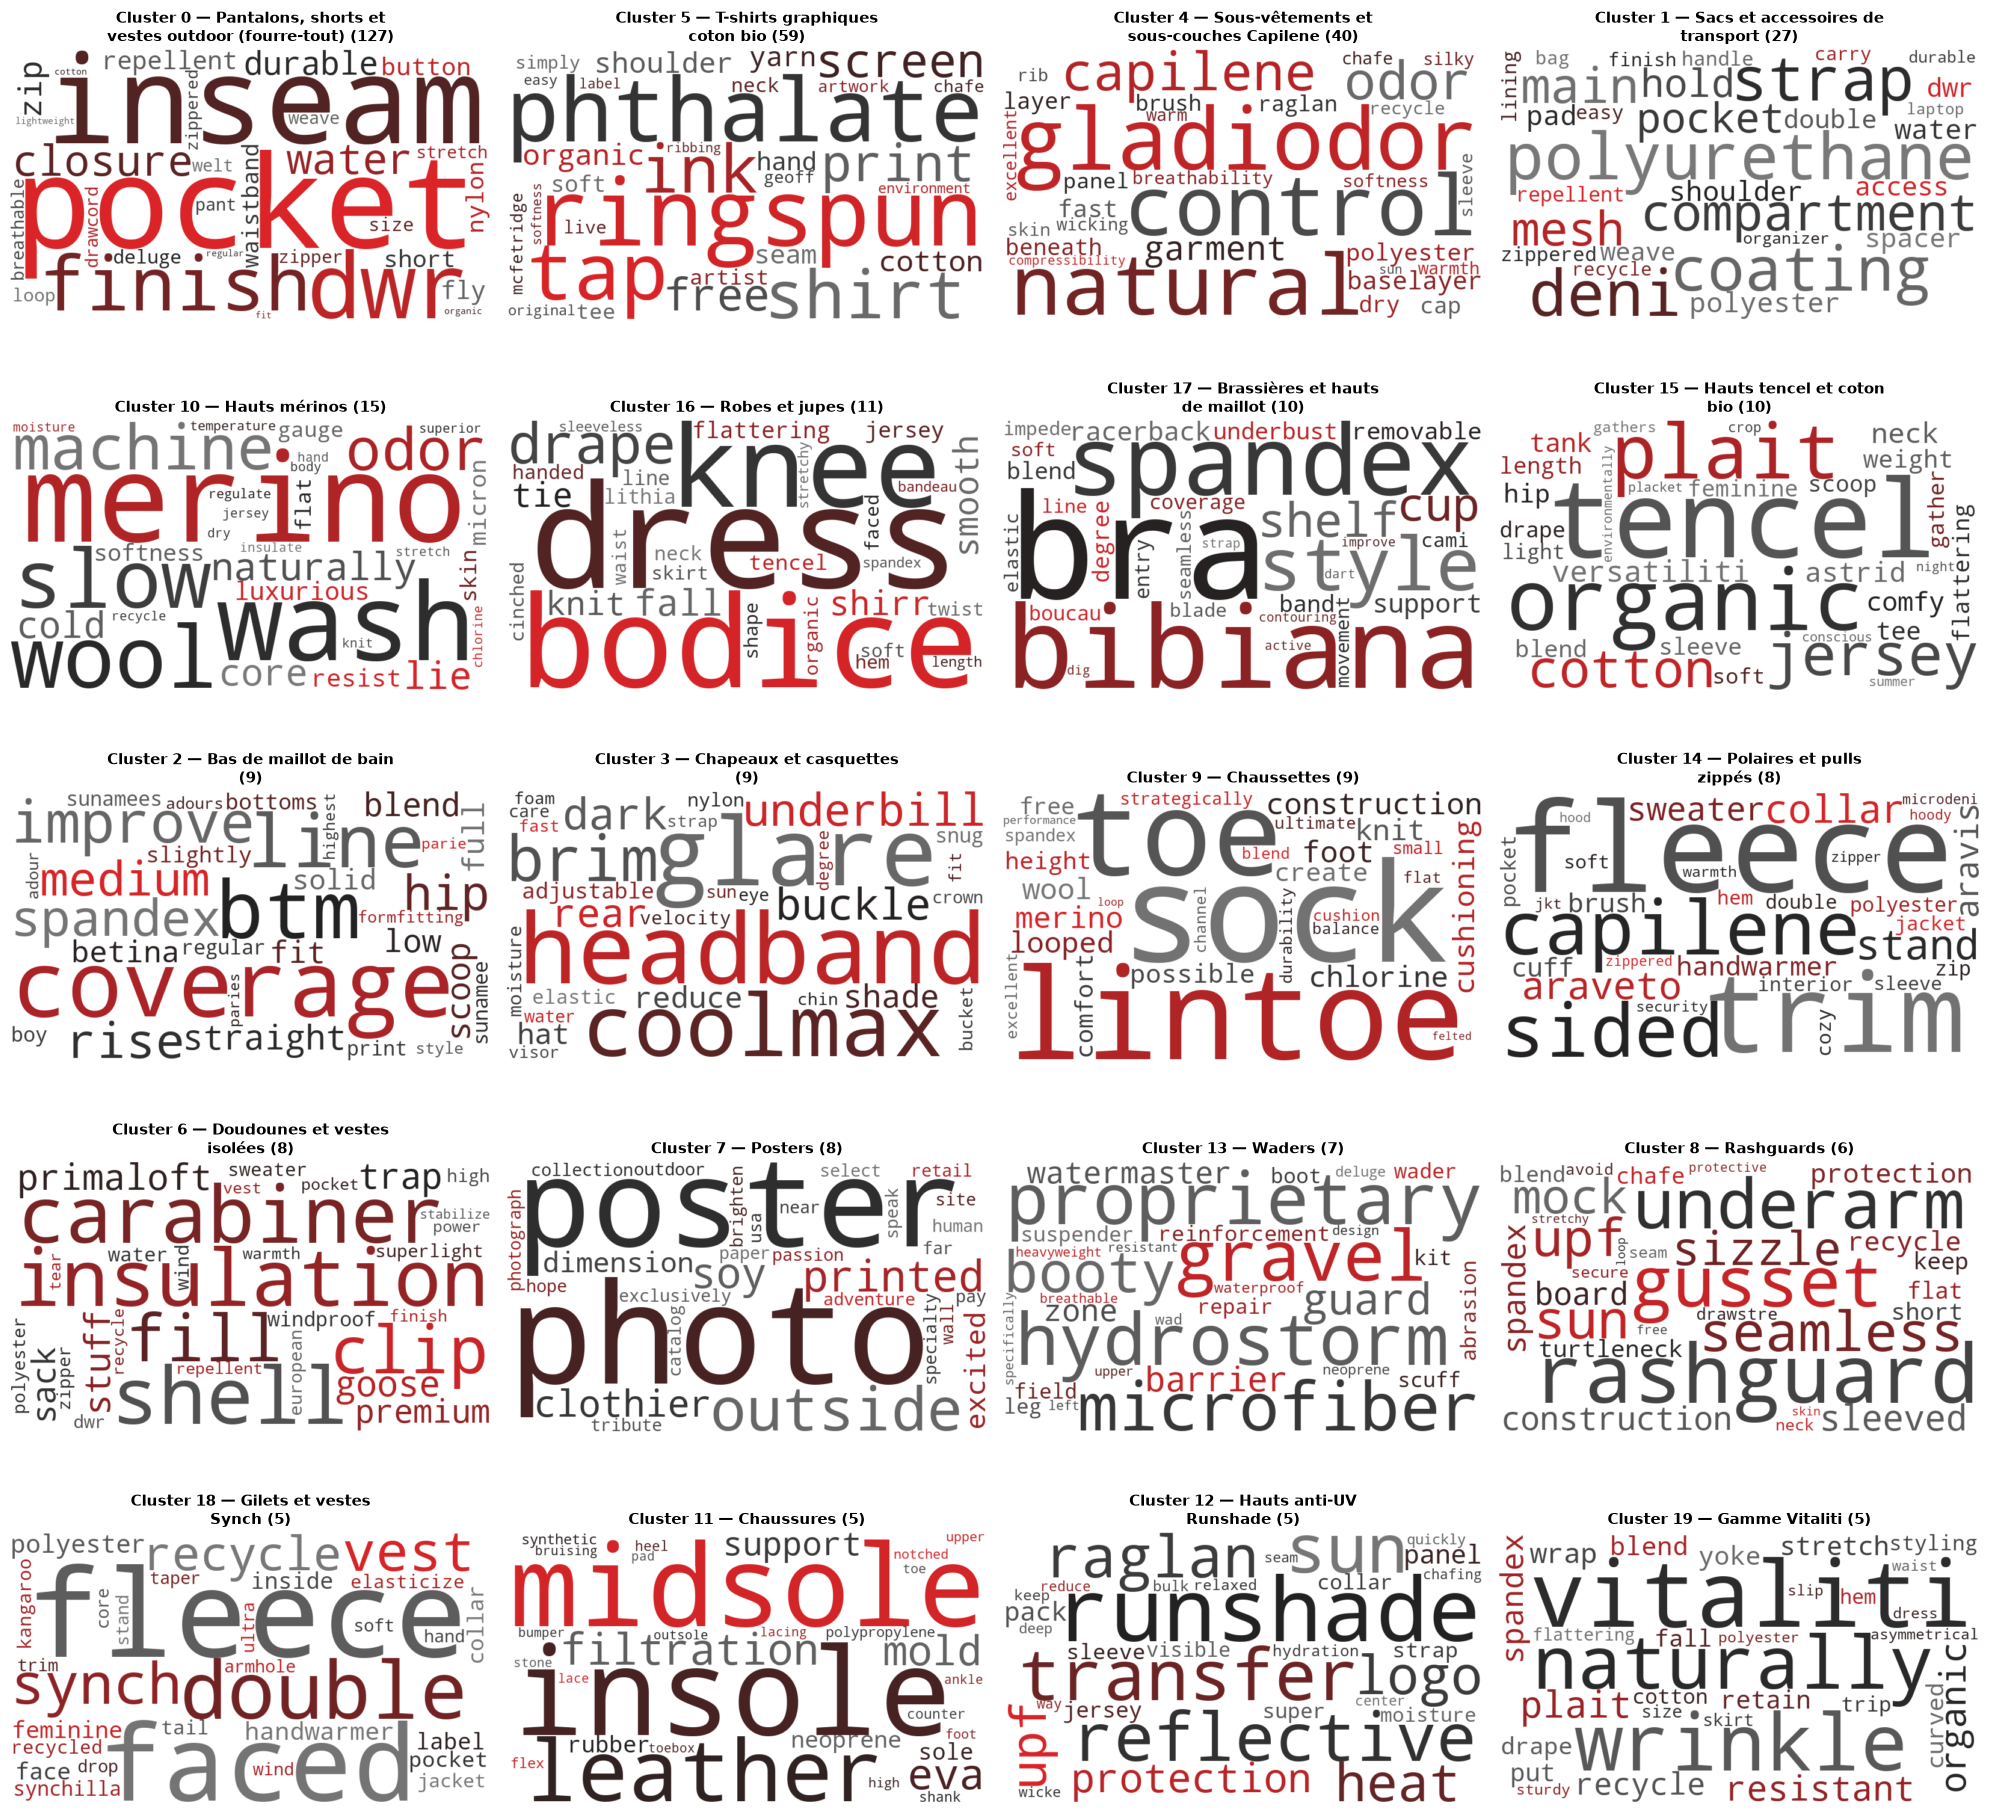

WordClouds des clusters sauvegardés dans assets/images.


In [49]:
def plot_wordclouds(weights_list, titles, n_cols=4, filename="wordclouds.png"):
    """
    Affiche une grille de WordClouds à partir de poids de termes.

    Paramètres :
        - weights_list : list[dict]
            Un dictionnaire {terme : poids} par WordCloud
        - titles : list[str]
            Un titre par WordCloud
        - n_cols : int
            Nombre de colonnes de la grille
        - filename : str
            Nom du fichier image sauvegardé
    """
    n_rows = (len(weights_list) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(5 * n_cols, 3.8 * n_rows)
    )
    axes = np.atleast_1d(axes).flatten()

    for ax, weights, title in zip(axes, weights_list, titles):
        wc = WordCloud(
            background_color="white",
            max_words=30,
            colormap=tnf_cmap,
            width=800,
            height=450,
        ).generate_from_frequencies(weights)
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(
            textwrap.fill(title, 34), fontsize=11, fontweight="bold"
        )
        ax.axis("off")

    for ax in axes[len(weights_list):]:
        ax.axis("off")

    save_figure(filename)


cluster_titles = [
    f"Cluster {cid} — {CLUSTER_NAMES.get(cid, '')} "
    f"({(df['cluster'] == cid).sum()})"
    for cid in cluster_ids
]
plot_wordclouds(
    [get_term_weights((df["cluster"] == cid).values) for cid in cluster_ids],
    cluster_titles,
    filename="04_wordclouds_clusters.png",
)
print("WordClouds des clusters sauvegardés dans assets/images.")

**Interprétation** La silhouette de 0,215 est basse, ce qui est courant en cosinus sur des textes. Elle ne veut pas dire que les clusters sont incohérents : les 19 clusters hors cluster 0 correspondent à des familles de produits identifiables (chaussettes, posters, waders, sacs…). Le point faible est le cluster 0 : 127 produits (25 % du catalogue), un pot commun de pantalons, shorts et vestes. Le bruit (23 %) n'est pas forcément aberrant : le produit 2 « Active sport boxer briefs » y figure alors qu'il ressemble beaucoup au cluster 4 (similarité 0,52).

### 4. Système de recommandation

Pour un produit donné, on propose d'abord les produits du **même cluster**, classés par **similarité cosinus** décroissante.
Si le produit est un outlier (cluster -1) ou si son cluster compte moins de 5 autres produits, la liste est complétée par les produits les plus proches du catalogue.

In [50]:
# find_similar_items est définie dans src/recommender.py
similarity_matrix = build_similarity_matrix(tfidf_matrix)


def show_recommendations(item_id):
    """Affiche le produit consulté et ses recommandations."""
    recommended_ids = find_similar_items(item_id, df, similarity_matrix)
    row = df[df["id"] == item_id].iloc[0]

    print(f"Produit consulté (ID {item_id}) : {row['nom']}")
    print(f"Cluster : {row['cluster']}")
    print(row["description_nettoyee"][:150])
    print("-" * 50)
    print("Vous aimerez aussi :")
    position = df.index.get_loc(df.index[df["id"] == item_id][0])
    for rec_id in recommended_ids:
        rec_position = df.index.get_loc(df.index[df["id"] == rec_id][0])
        rec = df.iloc[rec_position]
        sim = similarity_matrix[position, rec_position]
        print(
            f"  - ID {rec_id:>3} | {rec['nom']} "
            f"(cluster {rec['cluster']}, similarité {sim:.2f})"
        )

### 4.1 Test automatique (reproductible)

In [51]:
sample_id = (
    df[df["cluster"] != -1]
    .sample(1, random_state=RANDOM_STATE)["id"]
    .iloc[0]
)
show_recommendations(sample_id)

# --- Cas d'un outlier ---
print("\n" + "=" * 50)
outlier_id = df.loc[df["cluster"] == -1, "id"].iloc[0]
show_recommendations(outlier_id)

Produit consulté (ID 350) : Shop pants
Cluster : 0
shop pant long home truck inside shop pants garment wash organic cotton canvas tool resistant break easily shaped waist jean style pocketing steel riv
--------------------------------------------------
Vous aimerez aussi :
  - ID 119 | Shop pants (cluster 0, similarité 1.00)
  - ID 118 | Shop pants (cluster 0, similarité 0.99)
  - ID 391 | Relax fit organic ctn jeans-long (cluster 0, similarité 0.33)
  - ID 110 | Relax fit organic ctn jeans-shor (cluster 0, similarité 0.33)
  - ID 108 | Reg fit organic ctn jeans-long (cluster 0, similarité 0.33)

Produit consulté (ID 2) : Active sport boxer briefs
Cluster : -1
active sport boxer brief skin glory require movement boxer decide poach route form fit active sport boxer briefs breathable polyester recycle fabric f
--------------------------------------------------
Vous aimerez aussi :
  - ID   3 | Active sport briefs (cluster 4, similarité 0.52)
  - ID   1 | Active classic boxers (cluster 4,

### 4.2 Mode interractif (input utilisateur)

In [52]:
# L'utilisateur saisit l'ID d'un produit
# pour obtenir des recommandations
user_input = input(
    f"Entrez l'ID d'un produit ({df['id'].min()} à {df['id'].max()}) : "
)

try:
    print()
    show_recommendations(int(user_input))
except ValueError:
    print(
        f"ID invalide. Veuillez entrer "
        f"un nombre entre {df['id'].min()} et {df['id'].max()}."
    )


Produit consulté (ID 300) : Active briefs
Cluster : -1
active brief beat heat bali skin favorite cirque ultrasoft lightweight brief provide exceptional stretch moisture management keep comfortable dry glid
--------------------------------------------------
Vous aimerez aussi :
  - ID 155 | Active hipster (cluster -1, similarité 0.62)
  - ID 299 | Active boy shorts (cluster -1, similarité 0.45)
  - ID   3 | Active sport briefs (cluster 4, similarité 0.30)
  - ID   2 | Active sport boxer briefs (cluster -1, similarité 0.24)
  - ID 495 | Active briefs (cluster 4, similarité 0.23)


**Interprétation** Pour un produit classé, les suggestions viennent de son cluster ; pour un outlier, elles viennent des plus proches voisins du catalogue (produit 2 : 4 sur 5 dans le cluster 4). D'après la règle décrite, environ 27 % des fiches reposent sur ce repli : le bruit (117) et les clusters de 5 produits (clusters 11, 12, 18, 19 : 20 produits).

### 4.3 Évaluation du recommandeur

La similarité cosinus moyenne entre un produit et ses 5 recommandations est comparée à la similarité moyenne entre deux produits du catalogue (référence « au hasard »).

In [53]:
id_to_position = {pid: pos for pos, pid in enumerate(df["id"])}

reco_similarities = []
for item_id in df["id"]:
    position = id_to_position[item_id]
    recs = find_similar_items(item_id, df, similarity_matrix)
    reco_similarities.extend(
        similarity_matrix[position, id_to_position[r]] for r in recs
    )

n_items_total = len(df)
random_baseline = (
    (similarity_matrix.sum() - n_items_total)
    / (n_items_total * (n_items_total - 1))
)

mean_reco = np.mean(reco_similarities)
print(f"Similarité moyenne des recommandations : {mean_reco:.3f}")
print(
    f"Similarité moyenne entre deux produits au hasard : "
    f"{random_baseline:.3f}"
)
print(f"Gain : x{mean_reco / random_baseline:.1f}")

Similarité moyenne des recommandations : 0.477
Similarité moyenne entre deux produits au hasard : 0.070
Gain : x6.8


**Interprétation** Les recommandations sont ×6,8 plus proches que deux produits pris au hasard (0,477 contre 0,070). C'est un contrôle de bon sens, non une mesure de qualité : les suggestions maximisent la similarité par construction. La borne haute (5 plus proches voisins sans contrainte de cluster) donne l'écart dû au passage par les clusters. La vraie validation serait un test auprès d'utilisateurs (taux de clic).

## 5. Topic modeling (LSA)

`TruncatedSVD` sur la matrice TF-IDF. On compare 10, 15 et 20 composantes avant de choisir.

In [54]:
for n in [10, 15, 20]:
    svd_test = TruncatedSVD(n_components=n, random_state=RANDOM_STATE)
    svd_test.fit(tfidf_matrix)
    print(
        f"{n} composantes : variance expliquée = "
        f"{svd_test.explained_variance_ratio_.sum() * 100:.1f} %"
    )

10 composantes : variance expliquée = 20.4 %
15 composantes : variance expliquée = 25.7 %
20 composantes : variance expliquée = 30.1 %


In [55]:
# 15 composantes : bon compromis entre variance expliquée et lisibilité
n_topics = 15
lsa_model = TruncatedSVD(
    n_components=n_topics, random_state=RANDOM_STATE
)

# Nom de variable imposé par l'énoncé
topic_encoded_df = pd.DataFrame(
    lsa_model.fit_transform(tfidf_matrix),
    columns=[f"topic_{i}" for i in range(1, n_topics + 1)],
    index=df.index,
)
print(f"Matrice topic : {topic_encoded_df.shape}")

variance_totale = lsa_model.explained_variance_ratio_.sum() * 100
print(f"Variance expliquée totale : {variance_totale:.1f} %")


def display_topics(model, feat_names, no_top_words):
    """Affiche les mots-clés de chaque topic LSA."""
    print("\nThèmes identifiés :\n")
    for topic_idx, topic in enumerate(model.components_):
        term_indices = topic.argsort()[:-no_top_words - 1:-1]
        keywords = [feat_names[i] for i in term_indices]
        print(
            f"Topic {topic_idx + 1}: "
            f"{', '.join(keywords)}"
        )


display_topics(lsa_model, feature_names, 10)

Matrice topic : (500, 15)
Variance expliquée totale : 25.7 %

Thèmes identifiés :

Topic 1: pocket, organic, cotton, polyester, soft, seam, shirt, durable, recycle, shoulder
Topic 2: ringspun, phthalate, tap, shirt, ink, print, organic, cotton, screen, free
Topic 3: odor, control, merino, gladiodor, capilene, natural, knit, beneath, softness, wool
Topic 4: inseam, button, organic, cotton, short, fly, size, welt, canvas, jean
Topic 5: merino, wool, wash, machine, slow, naturally, lie, core, resist, cold
Topic 6: spandex, organic, line, coverage, tencel, blend, hem, hip, neck, jersey
Topic 7: spandex, coverage, sun, upf, blend, nylon, protection, support, strap, rise
Topic 8: photo, poster, outside, printed, usa, human, outdoor, specialty, site, dimension
Topic 9: strap, polyurethane, coating, compartment, mesh, pad, main, access, organic, hold
Topic 10: sun, upf, protection, collar, shirt, reflective, sleeve, transfer, logo, heat
Topic 11: barrier, waterproof, layer, proprietary, hydros

### 5.1 Topic principal de chaque produit

Le premier axe de la LSA capte le vocabulaire « moyen » du catalogue (poches, coton, polyester…) : avec un simple `argmax` sur les valeurs brutes, **près de la moitié (47%)** tombent dans le topic 1. On **standardise chaque topic** (z-score) avant l'`argmax` : le topic principal est alors celui où le produit est le plus au-dessus de la moyenne du catalogue.

In [56]:
raw_main_topic = topic_encoded_df.to_numpy().argmax(axis=1) + 1
print("Topic dominant, valeurs brutes :")
print(pd.Series(raw_main_topic).value_counts().sort_index().to_dict())

topic_zscores = (
    (topic_encoded_df - topic_encoded_df.mean()) / topic_encoded_df.std()
)
# +1 pour indexer à partir de 1
df["main_topic"] = topic_zscores.to_numpy().argmax(axis=1) + 1

print("\nTopic dominant, après standardisation :")
print(df["main_topic"].value_counts().sort_index())

Topic dominant, valeurs brutes :
{1: 235, 2: 61, 3: 34, 4: 26, 5: 11, 6: 29, 7: 12, 8: 8, 9: 27, 10: 16, 11: 7, 12: 23, 14: 11}

Topic dominant, après standardisation :
main_topic
1     32
2     61
3     34
4     50
5     15
6     52
7     43
8      8
9     41
10    36
11    23
12    45
13    19
14    14
15    27
Name: count, dtype: int64


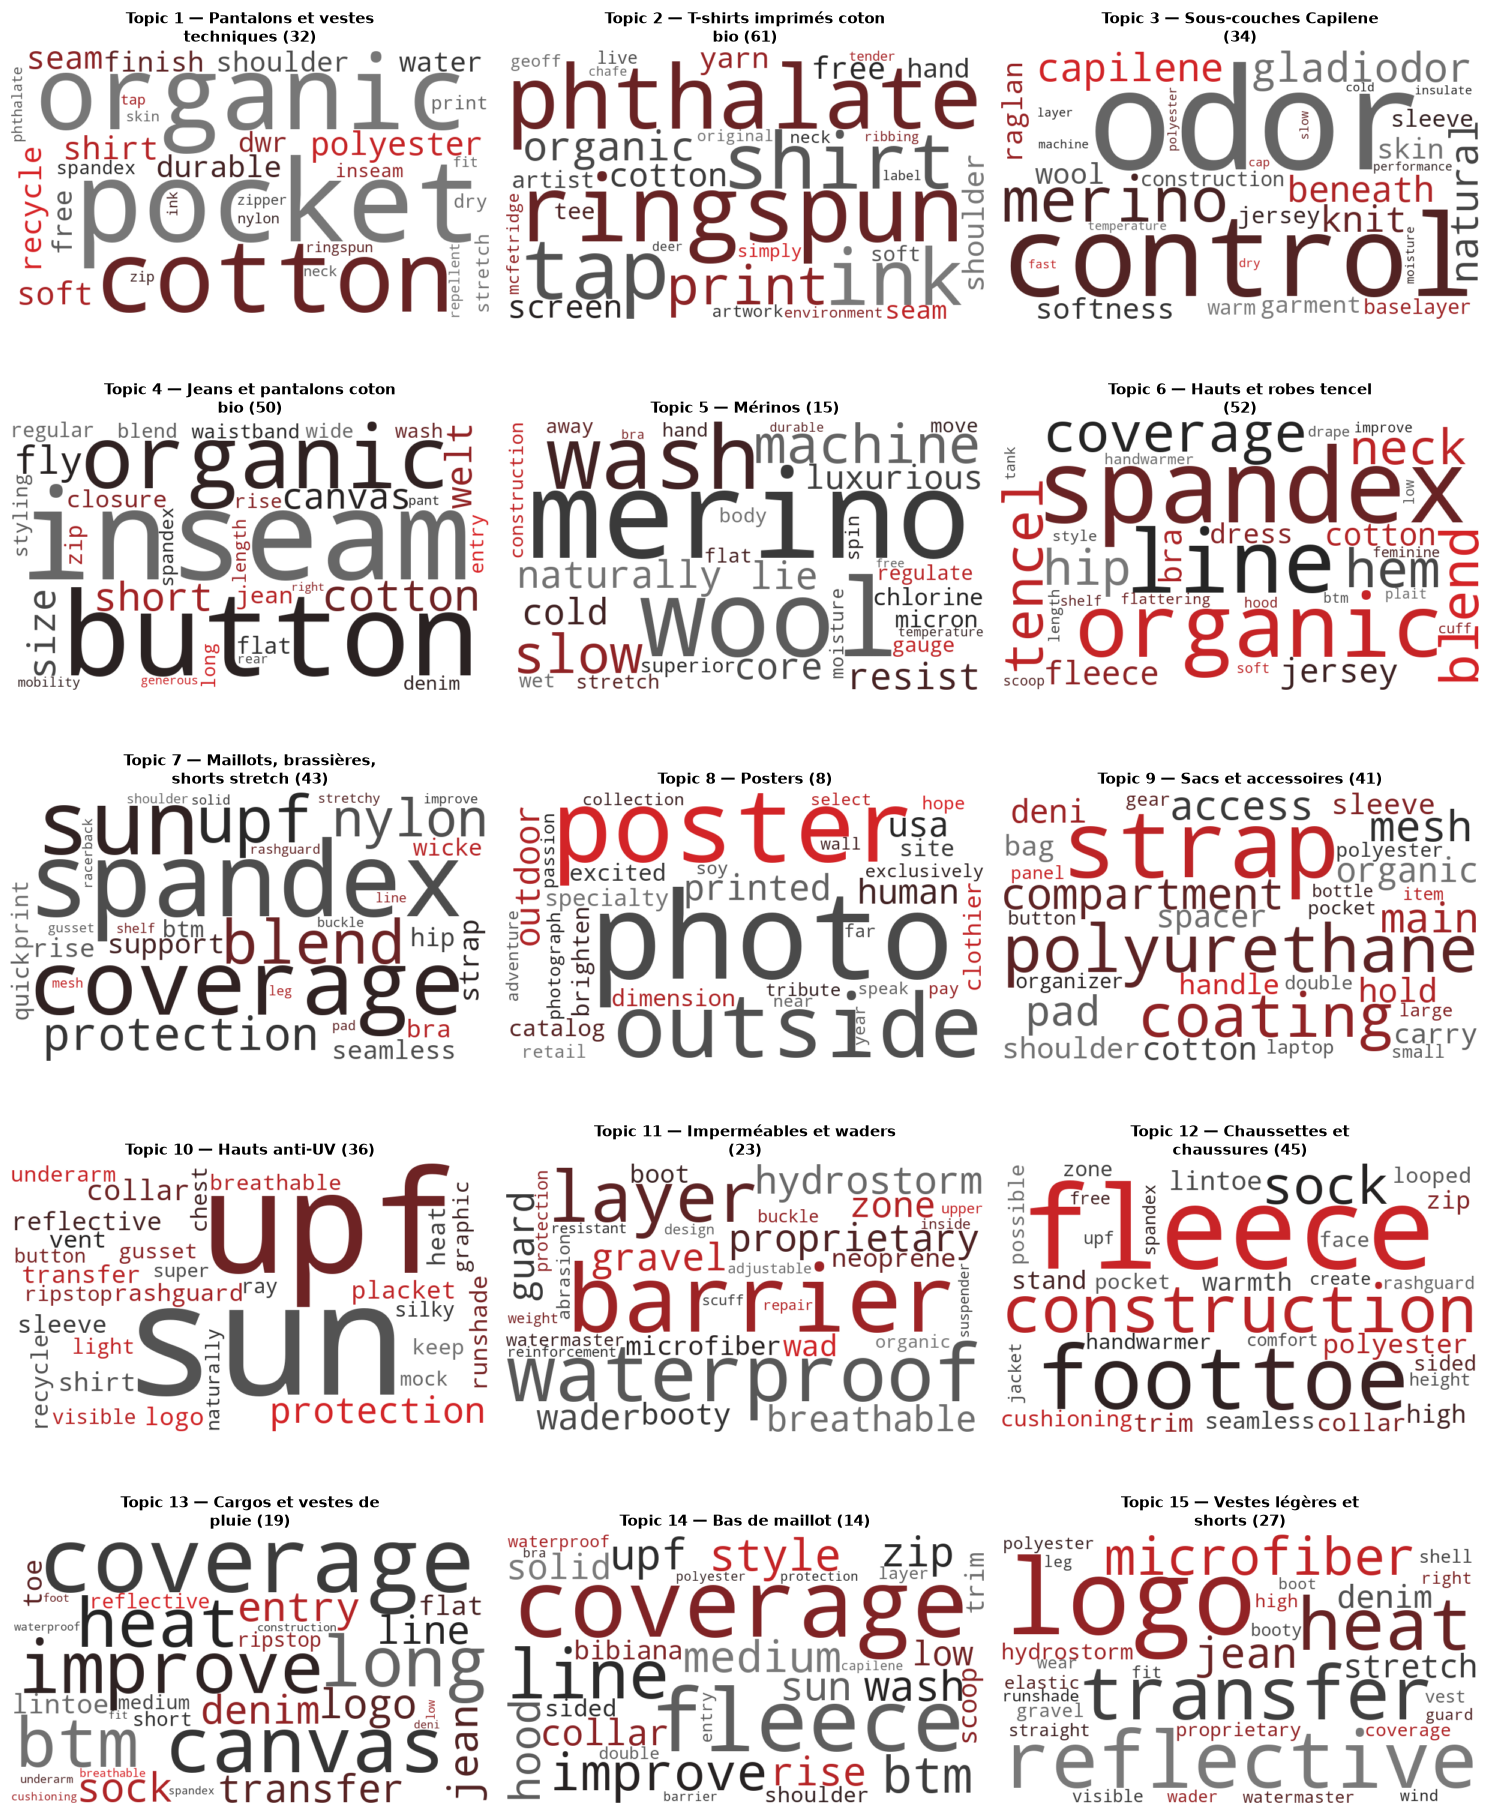

WordClouds des topics sauvegardés dans assets/images.


In [ ]:
TOPIC_NAMES = {
    1: 'Pantalons et vestes techniques',
    2: 'T-shirts imprimés coton bio',
    3: 'Sous-couches Capilene',
    4: 'Jeans et pantalons coton bio',
    5: 'Mérinos',
    6: 'Hauts et robes tencel',
    7: 'Maillots, brassières, shorts stretch',
    8: 'Posters',
    9: 'Sacs et accessoires',
    10: 'Hauts anti-UV',
    11: 'Imperméables et waders',
    12: 'Polaires, chaussettes et chaussuress',
    13: 'Cargos et vestes de pluie',
    14: 'Bas de maillot',
    15: 'Vestes légères et shorts',
}

topic_weights = []
for topic_idx, topic in enumerate(lsa_model.components_):
    top = topic.argsort()[::-1][:30]
    topic_weights.append(
        {feature_names[i]: topic[i] for i in top if topic[i] > 0}
    )

topic_titles = [
    f"Topic {i + 1} — {TOPIC_NAMES.get(i + 1, '')} "
    f"({(df['main_topic'] == i + 1).sum()})"
    for i in range(n_topics)
]
plot_wordclouds(
    topic_weights, topic_titles, n_cols=3, filename="05_wordclouds_topics.png"
)
print("WordClouds des topics sauvegardés dans assets/images.")

**Interprétation** Les 15 topics ne résument que 25,7 % de la variance, ce qui est normal sur un TF-IDF creux. Chaque composante supplémentaire apporte environ 1 point (+5,3 points de 10 à 15, +4,4 de 15 à 20) : il n'y a pas de coude, le choix de 15 repose sur la lisibilité. Les topics 1 à 11 sont lisibles (matières, familles de produits). Les topics 12 à 15 sont plus mixtes, et leurs noms sont plus subjectifs.

### 5.2 Clusters DBSCAN et topics LSA : points de recoupement

In [58]:
cross_tab = pd.crosstab(
    df.loc[df["cluster"] != -1, "cluster"],
    df.loc[df["cluster"] != -1, "main_topic"],
)
display(cross_tab)

# Pureté : part des produits d'un cluster dont le topic principal
# est le topic majoritaire du cluster
purity = cross_tab.max(axis=1).sum() / cross_tab.to_numpy().sum()
print(f"Pureté clusters / topics : {purity * 100:.1f} %")

main_topic,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cluster,,,,,,,,,,,,,,,
0,31,0,0,37,0,1,13,0,0,1,11,0,18,1,14
1,0,0,0,0,0,0,0,0,26,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0,0,0,0,9,0
3,0,0,0,0,0,0,4,0,1,1,1,0,1,0,1
4,0,0,34,0,0,0,1,0,0,0,0,5,0,0,0
5,0,59,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8
7,0,0,0,0,0,0,0,8,0,0,0,0,0,0,0
8,0,0,0,0,0,0,1,0,0,5,0,0,0,0,0


Pureté clusters / topics : 71.0 %


**Interprétation** 71 % des produits classés ont pour topic principal celui majoritaire de leur cluster. Hors cluster 0, cette pureté monte à 92 % (235/256) : les deux méthodes s'accordent donc sur les familles nettes (cluster 5 ↔ topic 2, cluster 1 ↔ topic 9, cluster 2 ↔ topic 14). Le cluster 0 est réparti sur 6 topics (jeans et pantalons 37, techniques 31, cargos 18, vestes 14, stretch 13, imperméables 11) : le topic permet de le subdiviser. LSA attribue en outre un thème aux 117 produits que DBSCAN laisse en bruit. Les deux méthodes ne sont pas indépendantes, car elles partent du même TF-IDF.

## 6. Conclusion et limites
1. **Le catalogue se structure en familles de produits nettes** (20 clusters, 77 % des produits classés), sauf un cluster "pot commun" (25 %).
2. **La recommandation est cohérente** (×6,8 vs hasard), à valider sur des usages réels.
3. **LSA complète DBSCAN** : thèmes pour 100 % du catalogue, et subdivision du cluster 0.
4. **Limites** : silhouette basse (0,215), un seul couple de paramètres valide, quasi-doublons dans les recommandations, topics 12 à 15 peu lisibles, 500 fiches seulement.